# Insurance Claims Data Processing Pipeline

This notebook builds a clean, leakage-free dataset for the recovery-risk fraud
model from the raw Al Hilal Takaful Excel exports, step by step, with explanations
and charts at every stage.

**Pipeline stages:**
1. Locate and load the raw Excel workbooks (claims + beneficiaries)
2. Clean and standardize columns (join keys, dates, financial amounts)
3. Apply business logic (status definitions, valid/excluded split, beneficiary merge
   on name+DOB, delete post-termination and missing-core-field rows, recovery sub-table)
4. Export processed CSVs
5. Explore the result visually (volumes, status mix, money flows, trends, demographics,
   class imbalance, provider recovery risk)
6. Build an ML-ready export: leakage-safe feature engineering, encoding, scaling

## 0. Setup

Standard imports plus a small chart style block (colors picked from a colorblind-safe categorical palette).

In [1]:

import re
import shutil
import tempfile
import zipfile
import os
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 60)
pd.set_option("mode.copy_on_write", True)  # avoid eager full-frame copies on drop/filter/assign

# --- Chart styling: fixed-order categorical palette (colorblind-safe) ---
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQUENTIAL_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10.5,
    "figure.dpi": 100,
})


def fmt_thousands(ax, axis="y"):
    formatter = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


## 1. Paths & metadata

Where the raw workbooks live, and the reference dictionaries used later (status
definitions, financial column list, column-name aliases, the anchor text used to
locate the real header row under the title rows on each sheet).

In [2]:

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = BASE_DIR / "data"
RAW_CLAIMS_DIR = DATA_DIR / "raw" / "utilization"
RAW_BENEF_DIR = DATA_DIR / "raw" / "beneficiaries"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("RAW_CLAIMS_DIR:", RAW_CLAIMS_DIR.resolve())
print("  contains:", sorted(f.name for f in RAW_CLAIMS_DIR.iterdir() if f.is_file()))
print("RAW_BENEF_DIR:", RAW_BENEF_DIR.resolve())
print("  contains:", sorted(f.name for f in RAW_BENEF_DIR.iterdir() if f.is_file()))


RAW_CLAIMS_DIR: C:\Users\Chayma\Desktop\my_insurance_project\data\raw\utilization
  contains: ['UR UY-2014 - NAS.xlsx', 'UTILIZ as at JAN 2014.xlsx', 'Utilization Report - UY-2014 Al Hilal Takaful.xlsx', 'Utilization Report - UY-2015 Al Hilal Takaful.xlsx']
RAW_BENEF_DIR: C:\Users\Chayma\Desktop\my_insurance_project\data\raw\beneficiaries
  contains: ['AHT 2014 A.xlsx', 'AHT 2014 B.xlsx', 'AHT 2015 A.xlsx', 'AHT 2015 B.xlsx', 'AHT 2016 A.xlsx']


In [3]:

STATUS_DEFINITIONS = {
    "Initial": "Authorization entered in NAS MAIN system or Direct Claim in initial processing stage",
    "Authorized": "Authorization issued in JET / E-Claim only",
    "Validated": "A Non-E-Claim batched and entered in the system before processing",
    "Pending": "Claim entered and decision pended for different reasons",
    "Processed": "Claims entered and decision made",
    "Closed": "Decision checked by system for limits/sublimits; ready for payment",
    "Not Closed & Pended (Partial)": "Internal status (e.g., Maternity); pending further adjudication regarding recovery",
    "PO Issued": "All claims previously closed included in Payment Orders for settlement",
    "Settled": "All claims for which payment has been dispatched to provider/beneficiary",
    "Rejected": "All authorizations which were rejected",
    "Void": "An authorization issued but not utilized",
    "Pending Validation": "Requests finished by provider and sent to Claim Center for approval",
    "Required Further Details": "Requests sent back to provider for more information",
    "Request Forwarded": "Requests forwarded between users but not finalized",
    "Replied Further Details": "Requests responded back by provider",
    "Pending With Payer": "Requests escalated to Payer",
    "Pending For 2nd Opinion": "Requests pended for second opinion",
}

# NOTE: BENEFICIARYIDENTIFIER (claims side) and BENEFICIARYID (beneficiary side) look
# like a matching ID pair but are NOT — they are two different identifier systems
# (a short hex code vs. a sequential numeric ID) and never overlap. Joining on them
# silently produces a 100%-empty beneficiary merge. The reliable shared key across
# both file families is beneficiary full name + date of birth.
BENEF_NAME_COL = "BENEFICIARY"
BENEF_DOB_COL = "DOB"

FINANCIAL_COLS = [
    "PAYERAMOUNTCLAIMED", "BENEFICIARYAMOUNTCLAIMED", "TOTALAMOUNTCLAIMED",
    "TOTALPAYABLE", "PAYERSHARE", "BENEFICIARYSHAREAPPROVED",
    "DEDUCTIONAMOUNT", "RECOVERY/EX-GRATIA",
]

COLUMN_ALIASES = {"RECOVERY": "RECOVERY/EX-GRATIA"}

HEADER_ANCHORS = ("CONTRACT", "BENEFICIARYID")
MAX_TITLE_ROWS_TO_SCAN = 15
SERVICE_DATE_COL = "TXNDATE"
POLICY_EXPIRY_COL = "EXPIRYDATE"

# Fields the fraud/recovery model actually needs at submission time (patient profile,
# diagnosis, provider, claim amount, dates). A row missing any of these is unusable
# for modeling, so it gets DROPPED rather than imputed/filled.
CORE_REQUIRED_COLS = [
    "TOTALAMOUNTCLAIMED", "TXNDATE", "STATUS", "PROVIDERTYPE", "CLAIMID", "ICD CHAPTER",
]

# Columns dropped outright if more than this share of rows is missing — the source
# workbooks never reliably captured them, so keeping/imputing them would add noise,
# not signal (e.g. REINSURER, NATIONALIDENTITYNO).
SPARSE_COLUMN_DROP_THRESHOLD = 0.97

# Exempt from the sparse-column drop even if >=SPARSE_COLUMN_DROP_THRESHOLD missing:
# LOS is genuinely blank for outpatient claims and only populated for inpatient
# stays — that's a real "not applicable", not a data-quality gap, and an unusually
# long stay is a classic fraud signal worth keeping.
SPARSE_COLUMN_ALLOWLIST = {"LOS"}

## 2. Helper functions

These mirror `process_data.py` exactly:
- **`strip_defined_names`** works around an openpyxl crash on legacy workbooks that
  have a corrupted "defined name" (named range) — it makes a cleaned temp copy.
- **`detect_header_row`** scans the first rows of a sheet for the real header, since
  the raw exports have title rows above the actual column headers.
- **`load_workbook_sheets`** opens every `.xlsx` in a folder and loads every sheet
  inside it, tagging each row with which sheet/file it came from.

In [4]:

_TEMP_CLEANED_FILES = []


def strip_defined_names(src_path):
    tmp_fd, tmp_path = tempfile.mkstemp(suffix=".xlsx")
    os.close(tmp_fd)
    shutil.copy(src_path, tmp_path)
    try:
        with zipfile.ZipFile(tmp_path, "r") as zin:
            contents = {n: zin.read(n) for n in zin.namelist()}
        if "xl/workbook.xml" in contents:
            xml = contents["xl/workbook.xml"].decode("utf-8", errors="replace")
            cleaned_xml = re.sub(r"<definedNames>.*?</definedNames>", "", xml, flags=re.DOTALL)
            if cleaned_xml != xml:
                print(f"    -> '{Path(src_path).name}' had defined names that can crash openpyxl on read; stripped them from a temp copy.")
                contents["xl/workbook.xml"] = cleaned_xml.encode("utf-8")
                with zipfile.ZipFile(tmp_path, "w", zipfile.ZIP_DEFLATED) as zout:
                    for name, data in contents.items():
                        zout.writestr(name, data)
    except Exception:
        pass
    _TEMP_CLEANED_FILES.append(tmp_path)
    return Path(tmp_path)


def get_readable_path(path):
    return strip_defined_names(path)


def find_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


def detect_header_row(raw_df, anchors=HEADER_ANCHORS, max_rows=MAX_TITLE_ROWS_TO_SCAN):
    scan_limit = min(max_rows, len(raw_df))
    for i in range(scan_limit):
        row_cells = raw_df.iloc[i].astype(str).str.strip().str.upper().tolist()
        if all(any(anchor in cell for cell in row_cells) for anchor in anchors):
            return i
    return None


def read_excel_robust(file, sheet_name, header=None, nrows=None):
    try:
        return pd.read_excel(file, sheet_name=sheet_name, header=header, nrows=nrows, engine="calamine")
    except Exception:
        return pd.read_excel(file, sheet_name=sheet_name, header=header, nrows=nrows, engine="openpyxl")


def load_tagged_sheet(file, sheet_name, tag_col, display_name=None):
    raw_preview = read_excel_robust(file, sheet_name, header=None, nrows=MAX_TITLE_ROWS_TO_SCAN)
    header_row = detect_header_row(raw_preview)
    if header_row is None:
        print(f"  WARNING: could not find a header row in sheet '{sheet_name}' of {display_name or file.name} — skipping this sheet.")
        return None
    df = read_excel_robust(file, sheet_name, header=header_row)
    df.columns = df.columns.str.strip()
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items() if k in df.columns})
    df[tag_col] = sheet_name
    df["source_file"] = display_name or file.name
    print(f"  Loaded sheet '{sheet_name}' from {display_name or file.name}: {len(df):,} rows (header found at row {header_row + 1})")
    return df


def load_workbook_sheets(directory, tag_col):
    files = sorted(
        {f.resolve() for f in directory.iterdir() if f.is_file() and f.suffix.lower() == ".xlsx"},
        key=lambda f: f.name,
    )
    frames = []
    for file in files:
        try:
            readable_file = get_readable_path(file)
            try:
                sheet_names = pd.ExcelFile(readable_file, engine="calamine").sheet_names
            except Exception:
                sheet_names = pd.ExcelFile(readable_file, engine="openpyxl").sheet_names
        except Exception as e:
            print(f"  Error opening {file.name}: {e}")
            continue
        for sheet_name in sheet_names:
            try:
                df_sheet = load_tagged_sheet(readable_file, sheet_name, tag_col, display_name=file.name)
                if df_sheet is not None and not df_sheet.empty:
                    frames.append(df_sheet)
            except Exception as e:
                print(f"  Error reading sheet '{sheet_name}' in {file.name}: {e}")
    return frames, len(files)


def optimize_dtypes(df):
    """Downcast a freshly-loaded claims/beneficiary frame to cut memory use.

    Claims data is heavily repetitive (status, provider, diagnosis, network names
    repeat across ~1M rows), so object columns become `category` dtype and 64-bit
    floats become 32-bit — typically an 80-90% memory reduction with no precision
    loss that matters for this data.
    """
    for col in df.columns:
        if df[col].dtype == object:
            n_unique = df[col].nunique(dropna=True)
            if n_unique / max(len(df), 1) < 0.5:
                df[col] = df[col].astype("category")
        elif df[col].dtype == "float64":
            df[col] = pd.to_numeric(df[col], downcast="float")
    return df


## 3. Load & combine claims data

Every sheet of every workbook in `data/raw/utilization/` is loaded and tagged with `REPORT_TYPE` (the sheet name it came from), then concatenated into one DataFrame.

In [5]:

claim_frames, n_claim_files = load_workbook_sheets(RAW_CLAIMS_DIR, tag_col="REPORT_TYPE")
print(f"\nFound {n_claim_files} claims workbook(s)")

if not claim_frames:
    raise FileNotFoundError("No valid claims data loaded. Please check data/raw/utilization.")

df_utilization = pd.concat(claim_frames, ignore_index=True, sort=False)
del claim_frames
gc.collect()
df_utilization = optimize_dtypes(df_utilization)
print(f"Combined claims dataset: {len(df_utilization):,} rows across report types: "
      f"{sorted(df_utilization['REPORT_TYPE'].unique())}")
print(f"Memory usage after dtype optimization: {df_utilization.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
df_utilization.head()


    -> 'UR UY-2014 - NAS.xlsx' had defined names that can crash openpyxl on read; stripped them from a temp copy.


  Loaded sheet 'Data' from UR UY-2014 - NAS.xlsx: 273,741 rows (header found at row 4)


  Loaded sheet 'Recovery' from UR UY-2014 - NAS.xlsx: 202 rows (header found at row 4)


  Loaded sheet 'PendingAuthorizations' from UR UY-2014 - NAS.xlsx: 30 rows (header found at row 4)


    -> 'UTILIZ as at JAN 2014.xlsx' had defined names that can crash openpyxl on read; stripped them from a temp copy.


...

C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\1571596121.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_utilization = pd.concat(claim_frames, ignore_index=True, sort=False)


C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\1571596121.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_utilization = pd.concat(claim_frames, ignore_index=True, sort=False)
C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\1571596121.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_utilization = pd.concat(claim_frames, ignore_index=True, sort=False)


Combined claims dataset: 1,017,993 rows across report types: ['Data', 'PendingAuthorizations', 'Recovery']


Memory usage after dtype optimization: 384 MB


,MASTERCONTRACT,BRANCH,REINSURER,CONTRACT,EFFECTIVEDATE,EXPIRYDATE,POLICYNO,PRINCIPAL,BENEFICIARY,DOB,GENDER,MARITAL STATUS,AGE,AGEBAND,NATIONALITY,EMPNO,CATEGORY,DEPENDENCY,BENEF-STATUS,NETWORK,NETWORK TYPE,REPORTING AUTHORITY,TXNDATE,DISCHARGEDATE,LOS,FOB,MEMBER START DATE,CHRONIC,PREEXISTING,CLAIMTYPE,...,RESUBMISSION,PROVIDERCOUNTRY,PROVIDER EMIRATE,PROVIDERTYPE,PROVIDER GROUP,PROVIDER,PAYERAMOUNTCLAIMED,BENEFICIARYAMOUNTCLAIMED,TOTALAMOUNTCLAIMED,TOTALPAYABLE,PAYERSHARE,BENEFICIARYSHAREAPPROVED,DEDUCTIONAMOUNT,RECOVERY/EX-GRATIA,RECOVERYTYPE,PAYABLE NON IP CONSULTATION,PO,ORDERDATE,CHEQUENBR,SETTLEDATE,CURRENCY,STATUS,CLAIM CATEGORY,ICD CHAPTER,ICD SUB CHAPTER,ASSESSMENT,REPORT_TYPE,source_file,Recovery Notes,RecoveryNotes
0,AL JURF Development Projects LLC,Main,NaN,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-01-04,2014-01-04 00:00:00,NaN,Dental,2014-01-01 00:00:00,No,No,Reimbursement,...,No,United Arab Emirates,Abu Dhabi,Polyclinic/Diagnostic Center,Group Not defined,Dr. Munir Silwadi Dental Center - Abu Dhabi,1500.00,0.00,1500.00,1200.00,1200.00,300.00,300.00,0.0,,0.0,73894.0,2014-01-29,38295,2014-02-05,Arab Emirates Dirham,Settled,Paid,Diseases of the digestive system (ICD9CM 520-5...,Diseases of oral cavity and salivary glands (K...,521.0 Dental Caries,Data,UR UY-2014 - NAS.xlsx,NaN,NaN
1,AL JURF Development Projects LLC,Main,NaN,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-01-06,2014-01-06 00:00:00,NaN,Dental,2014-01-01 00:00:00,No,No,Reimbursement,...,No,United Arab Emirates,Abu Dhabi,Polyclinic/Diagnostic Center,Group Not defined,Dr. Munir Silwadi Dental Center - Abu Dhabi,500.00,0.00,500.00,400.00,400.00,100.00,100.00,0.0,,0.0,73894.0,2014-01-29,38295,2014-02-05,Arab Emirates Dirham,Settled,Paid,Diseases of the digestive system (ICD9CM 520-5...,Diseases of oral cavity and salivary glands (K...,521.0 Dental Caries,Data,UR UY-2014 - NAS.xlsx,NaN,NaN
2,AL JURF Development Projects LLC,Main,NaN,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-06-07,2014-06-07 00:00:00,NaN,Out-Patient,2014-01-01 00:00:00,No,No,Network,...,No,United Arab Emirates,Dubai,Hospital,Cosmesurge & Emirates Hospital,Emirates Hospital - Dubai,804.75,50.00,854.75,804.74,804.74,50.00,0.01,0.0,,1.0,82714.0,2014-07-20,92444,2014-10-23,Arab Emirates Dirham,Settled,Paid,Diseases of the respiratory system (ICD9CM 460...,Acute upper respiratory infections (J00-J06)(4...,"J01.91 Acute recurrent sinusitis, unspecified",Data,UR UY-2014 - NAS.xlsx,NaN,NaN
3,AL JURF Development Projects LLC,Main,NaN,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-06-07,2014-06-07 00:00:00,NaN,Out-Patient,2014-01-01 00:00:00,No,No,Network,...,No,United Arab Emirates,Dubai,Hospital,Cosmesurge & Emirates Hospital,Emirates Hospital - Dubai,759.22,189.78,949.00,0.00,0.00,189.78,759.22,0.0,,0.0,83280.0,2014-08-03,93773,2014-11-01,Arab Emirates Dirham,Settled,Paid,Diseases of the respiratory system (ICD9CM 460...,Acute upper respiratory infections (J00-J06)(4...,"J01.91 Acute recurrent sinusitis, unspecified",Data,UR UY-2014 - NAS.xlsx,NaN,NaN
4,AL JURF Development Projects LLC,Main,NaN,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat

**Chart — rows loaded per source workbook.** Sanity check that every raw file actually contributed rows.

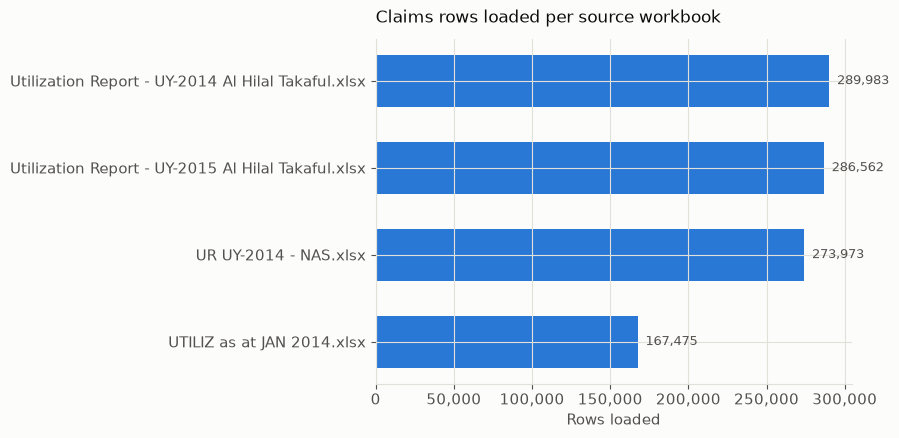

In [6]:

counts_by_file = df_utilization["source_file"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(counts_by_file.index[::-1], counts_by_file.values[::-1], color=CATEGORICAL[0], height=0.6)
ax.set_xlabel("Rows loaded")
ax.set_title("Claims rows loaded per source workbook", color=INK, fontsize=12, loc="left", pad=12)
fmt_thousands(ax, axis="x")
for bar, v in zip(bars, counts_by_file.values[::-1]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {v:,}", va="center", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()


## 4. Load & combine beneficiary data

Same process, applied to `data/raw/beneficiaries/`, tagged with `BENEF_SHEET` instead.

In [7]:

benef_frames, n_benef_files = load_workbook_sheets(RAW_BENEF_DIR, tag_col="BENEF_SHEET")
print(f"\nFound {n_benef_files} beneficiary workbook(s)")

df_beneficiaries = pd.concat(benef_frames, ignore_index=True, sort=False) if benef_frames else pd.DataFrame()
del benef_frames
gc.collect()
if not df_beneficiaries.empty:
    df_beneficiaries = optimize_dtypes(df_beneficiaries)
print(f"Combined beneficiaries dataset: {len(df_beneficiaries):,} rows")
df_beneficiaries.head()


  Loaded sheet 'Sheet1' from AHT 2014 A.xlsx: 32,560 rows (header found at row 3)


  Loaded sheet 'Sheet1' from AHT 2014 B.xlsx: 32,033 rows (header found at row 3)


  Loaded sheet 'Sheet1' from AHT 2015 A.xlsx: 41,027 rows (header found at row 3)


  Loaded sheet 'Sheet1' from AHT 2015 B.xlsx: 41,031 rows (header found at row 3)


    -> 'AHT 2016 A.xlsx' had defined names that can crash openpyxl on read; stripped them from a temp copy.


  Loaded sheet 'Data' from AHT 2016 A.xlsx: 13,330 rows (header found at row 3)

Found 5 beneficiary workbook(s)


Combined beneficiaries dataset: 159,981 rows


,PAYER,MASTERCONTRACT,CONTRACT,POLICYNUMBER,CONTRACTEFFDATE,CONTRACTEXPDATE,ENDORSEMENTID,ENDOTYPE,ENDORSEMENTDATE,ISSUEDATE,PRINCIPAL,BENEFICIARYID,BENEFICIARY,CARDNUMBER,NATIONALIDENTITYNO,NETWORK TYPE,NETWORK,STATUS,EMPNO,DEPENDENCY,GENDER,NATIONALITY,MARITALSTATUS,DOB,PRODUCT,CATEGORY,NETPREMIUM,GROSSPREMIUM,AGE,CURRENCY,BENEF_SHEET,source_file
0,Al Hilal Takaful,AL JURF Development Projects LLC,AL JURF Development Projects LLC,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,Abdi Awil Omar,2456594.0,Abdi Awil Omar,A1BC-499B-20D4-89F6,NaN,General Network,Hilal Tak.-GN-GEN. NET,Policy Expired,0776,Principal,Male,Somalia,Married,1982-01-01,Al Jurf Male/UMF,Male/UMF members,3995.0,4250.0,32.0,Arab Emirates Dirham,Sheet1,AHT 2014 A.xlsx
1,Al Hilal Takaful,AL JURF Development Projects LLC,AL JURF Development Projects LLC,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,Abdi Awil Omar,2456595.0,Nura Aidid Ismail,8627-22E3-A54C-2FBA,NaN,General Network,Hilal Tak.-GN-GEN. NET,Policy Expired,0776,Spouse,Female,Somalia,Married,1984-01-01,Al Jurf MF,Male/UMF members,3995.0,4250.0,30.0,Arab Emirates Dirham,Sheet1,AHT 2014 A.xlsx
2,Al Hilal Takaful,AL JURF Development Projects LLC,AL JURF Development Projects LLC,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,Abdi Awil Omar,2456596.0,Ahmed Abdi Awil Omar,3507-27F9-743D-85FC,NaN,General Network,Hilal Tak.-GN-GEN. NET,Policy Expired,0776,Child,Male,Somalia,Single,2008-10-08,Al Jurf Male/UMF,Male/UMF members,3995.0,4250.0,6.0,Arab Emirates Dirham,Sheet1,AHT 2014 A.xlsx
3,Al Hilal Takaful,AL JURF Development Projects LLC,AL JURF Development Projects LLC,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,Abdi Awil Omar,2456598.0,Maryam Abdirahman Awil,05AC-4D28-4D36-C233,NaN,General Network,Hilal Tak.-GN-GEN. NET,Policy Expired,0776,Child,Female,Somalia,Single,2013-08-22,Al Jurf Male/UMF,Male/UMF members,3995.0,4250.0,1.0,Arab Emirates Dirham,Sheet1,AHT 2014 A.xlsx
4,Al Hilal Takaful,AL JURF Development Projects LLC,AL JURF Development Projects LLC,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,Abdi Awil Omar,2456597.0,Mohamed Abdirahman Awil Omer,C6DC-AC35-20D1-9AFC,NaN,General Network,Hilal Tak.-GN-GEN. NET,Policy Expired,0776,Child,Male,Somalia,Single,2010-10-20,Al Jurf Male/UMF,Male/UMF members,3995.0,4250.0,4.0,Arab Emirates Dirham,Sheet1,AHT 2014 A.xlsx


## 5. Data cleaning & standardization

A reliable join key (normalized beneficiary name + DOB) is built on both sides; date columns are parsed; financial columns are coerced to numeric with a `_WAS_MISSING` flag recorded **before** filling NaNs with 0.0, so a genuine \$0 claim stays distinguishable from a blank/unparseable source cell.

In [8]:

date_cols_util = [c for c in df_utilization.columns if "DATE" in c.upper() or c.upper() == "DOB"]
for col in date_cols_util:
    df_utilization[col] = pd.to_datetime(df_utilization[col], errors="coerce")

if not df_beneficiaries.empty:
    date_cols_benef = [c for c in df_beneficiaries.columns if "DATE" in c.upper() or c.upper() == "DOB"]
    for col in date_cols_benef:
        df_beneficiaries[col] = pd.to_datetime(df_beneficiaries[col], errors="coerce")

# Build the real join key: normalized beneficiary name + DOB (see note in section 1 on
# why BENEFICIARYIDENTIFIER/BENEFICIARYID cannot be used).
def make_join_key(df):
    name = df[BENEF_NAME_COL].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
    dob = df[BENEF_DOB_COL].dt.strftime("%Y-%m-%d").fillna("UNKNOWN")
    return name + "|" + dob

has_join_cols_util = BENEF_NAME_COL in df_utilization.columns and BENEF_DOB_COL in df_utilization.columns
has_join_cols_benef = (
    not df_beneficiaries.empty
    and BENEF_NAME_COL in df_beneficiaries.columns
    and BENEF_DOB_COL in df_beneficiaries.columns
)

if has_join_cols_util:
    df_utilization["_JOIN_KEY"] = make_join_key(df_utilization)
    print("Claims join key: BENEFICIARY + DOB")

if has_join_cols_benef:
    df_beneficiaries["_JOIN_KEY"] = make_join_key(df_beneficiaries)
    df_beneficiaries = df_beneficiaries.drop_duplicates(subset=["_JOIN_KEY"])
    print(f"Beneficiary join key: BENEFICIARY + DOB ({len(df_beneficiaries):,} unique beneficiaries)")

missing_summary = {}
for col in FINANCIAL_COLS:
    if col in df_utilization.columns:
        parsed = pd.to_numeric(df_utilization[col], errors="coerce")
        n_missing = int(parsed.isna().sum())
        missing_summary[col] = n_missing
        if n_missing:
            df_utilization[col + "_WAS_MISSING"] = parsed.isna()
        df_utilization[col] = parsed.fillna(0.0)

if "STATUS" in df_utilization.columns:
    df_utilization["STATUS"] = df_utilization["STATUS"].astype(str).str.strip()

missing_summary

Claims join key: BENEFICIARY + DOB


Beneficiary join key: BENEFICIARY + DOB (99,038 unique beneficiaries)


{'PAYERAMOUNTCLAIMED': 12,
 'BENEFICIARYAMOUNTCLAIMED': 12,
 'TOTALAMOUNTCLAIMED': 12,
 'TOTALPAYABLE': 12,
 'PAYERSHARE': 12,
 'BENEFICIARYSHAREAPPROVED': 12,
 'DEDUCTIONAMOUNT': 12,
 'RECOVERY/EX-GRATIA': 12}

## 6. Business logic

**A.** Map each `STATUS` to its plain-English definition.

**B.** Split off `Rejected`/`Void` claims into their own frame instead of silently discarding them.

**C.** Left-join the valid claims onto beneficiary data using the name+DOB key, then drop
the resulting duplicate `_beneficiary`-suffixed columns (same fact as the claims-side
column) and any column that's still almost entirely empty (`SPARSE_COLUMN_DROP_THRESHOLD`).

**D.** Identify claims serviced *after* the policy's expiry date and **delete** them — a
claim serviced outside the covered period is not a valid case for a recovery model to
learn from, not just an audit footnote.

**E.** Drop rows missing a `CORE_REQUIRED_COLS` field — unusable for modeling either way.

**F.** Pull out the recovery/ex-gratia sub-table.

In [9]:

n_raw_claims = len(df_utilization)

if "STATUS" in df_utilization.columns:
    df_utilization["STATUS_DESCRIPTION"] = df_utilization["STATUS"].map(STATUS_DEFINITIONS).fillna("Unknown / Unmapped Status")

if "STATUS" in df_utilization.columns:
    is_excluded = df_utilization["STATUS"].isin(["Rejected", "Void"])
    df_valid_claims = df_utilization[~is_excluded].copy()
    df_excluded_claims = df_utilization[is_excluded].copy()
else:
    df_valid_claims = df_utilization.copy()
    df_excluded_claims = pd.DataFrame()

print(f"Valid claims: {len(df_valid_claims):,}  |  Excluded (Rejected/Void): {len(df_excluded_claims):,}")

del df_utilization
gc.collect()

# --- C. Merge on the name+DOB join key ---
if has_join_cols_benef and has_join_cols_util and "_JOIN_KEY" in df_valid_claims.columns:
    df_final = pd.merge(
        df_valid_claims, df_beneficiaries,
        on="_JOIN_KEY", how="left", suffixes=("", "_beneficiary"),
    )
    matched = df_final["BENEFICIARYID"].notna().sum() if "BENEFICIARYID" in df_final.columns else 0
    print(f"Beneficiary merge: {matched:,} / {len(df_final):,} claims matched to a beneficiary record")
else:
    df_final = df_valid_claims
    print("Skipped beneficiary merge (missing join columns on one or both sides).")

df_final = df_final.drop(columns=["_JOIN_KEY"], errors="ignore")

del df_valid_claims
if not df_beneficiaries.empty:
    del df_beneficiaries
gc.collect()

# Drop columns that only exist because of the merge and duplicate a claims-side fact
# (e.g. NETWORK_beneficiary repeating NETWORK) — keep the original, drop the copy.
dup_beneficiary_cols = [
    c for c in df_final.columns
    if c.endswith("_beneficiary") and c[: -len("_beneficiary")] in df_final.columns
]
if dup_beneficiary_cols:
    df_final = df_final.drop(columns=dup_beneficiary_cols)
    print(f"Dropped {len(dup_beneficiary_cols)} duplicate beneficiary-merge columns: {dup_beneficiary_cols}")

# Drop columns that are still almost entirely empty (source data never captured them).
sparse_cols = [
    c for c in df_final.columns
    if c not in SPARSE_COLUMN_ALLOWLIST and df_final[c].isna().mean() >= SPARSE_COLUMN_DROP_THRESHOLD
]
if sparse_cols:
    df_final = df_final.drop(columns=sparse_cols)
    print(f"Dropped {len(sparse_cols)} sparse columns (>={SPARSE_COLUMN_DROP_THRESHOLD:.0%} missing): {sparse_cols}")

# --- D. Post-termination claims: delete, don't just flag ---
n_before_termination_filter = len(df_final)
if SERVICE_DATE_COL in df_final.columns and POLICY_EXPIRY_COL in df_final.columns:
    is_post_termination = df_final[SERVICE_DATE_COL] > df_final[POLICY_EXPIRY_COL]
    n_post_termination = int(is_post_termination.sum())
    df_post_termination = df_final[is_post_termination].copy()
    df_final = df_final[~is_post_termination].copy()
    print(f"Deleted {n_post_termination:,} rows serviced after policy expiry (outside the covered period)")
else:
    n_post_termination = 0
    df_post_termination = pd.DataFrame()

# --- E. Drop rows missing a core, model-required field ---
n_before_core_filter = len(df_final)
core_cols_present = [c for c in CORE_REQUIRED_COLS if c in df_final.columns]
df_final = df_final.dropna(subset=core_cols_present)
n_dropped_core = n_before_core_filter - len(df_final)
print(f"Dropped {n_dropped_core:,} rows missing a core field {core_cols_present}")

# The *_WAS_MISSING flags (section 5) only ever flagged rows with an unparseable
# financial value — those same rows were also missing a core field (usually
# TOTALAMOUNTCLAIMED) and got deleted just above, so the flags can end up always
# False here. A flag with no variance left carries no signal; drop it.
dead_flag_cols = [
    c for c in df_final.columns
    if c.endswith("_WAS_MISSING") and df_final[c].nunique(dropna=False) <= 1
]
if dead_flag_cols:
    df_final = df_final.drop(columns=dead_flag_cols)
    print(f"Dropped {len(dead_flag_cols)} now-uninformative _WAS_MISSING flags (always the same value): {dead_flag_cols}")

df_final = df_final.reset_index(drop=True)

# --- F. Recovery/ex-gratia sub-table ---
df_recovery = df_final[df_final["RECOVERY/EX-GRATIA"] > 0].copy() if "RECOVERY/EX-GRATIA" in df_final.columns else pd.DataFrame()

print(f"\nFinal cleaned dataset: {len(df_final):,} rows, {df_final.shape[1]} columns "
      f"(started at {n_before_termination_filter:,} rows before this section)")
print(f"Recovery/ex-gratia rows: {len(df_recovery):,} ({len(df_recovery) / len(df_final) * 100:.3f}% of claims)")
df_final.head()

Valid claims: 1,017,993  |  Excluded (Rejected/Void): 0


Beneficiary merge: 944,205 / 1,017,993 claims matched to a beneficiary record


Dropped 16 duplicate beneficiary-merge columns: ['MASTERCONTRACT_beneficiary', 'CONTRACT_beneficiary', 'PRINCIPAL_beneficiary', 'BENEFICIARY_beneficiary', 'NETWORK TYPE_beneficiary', 'NETWORK_beneficiary', 'STATUS_beneficiary', 'EMPNO_beneficiary', 'DEPENDENCY_beneficiary', 'GENDER_beneficiary', 'NATIONALITY_beneficiary', 'DOB_beneficiary', 'CATEGORY_beneficiary', 'AGE_beneficiary', 'CURRENCY_beneficiary', 'source_file_beneficiary']


Dropped 3 sparse columns (>=97% missing): ['REINSURER', 'Recovery Notes', 'RecoveryNotes']


Deleted 9 rows serviced after policy expiry (outside the covered period)


Dropped 178,775 rows missing a core field ['TOTALAMOUNTCLAIMED', 'TXNDATE', 'STATUS', 'PROVIDERTYPE', 'CLAIMID', 'ICD CHAPTER']
Dropped 8 now-uninformative _WAS_MISSING flags (always the same value): ['PAYERAMOUNTCLAIMED_WAS_MISSING', 'BENEFICIARYAMOUNTCLAIMED_WAS_MISSING', 'TOTALAMOUNTCLAIMED_WAS_MISSING', 'TOTALPAYABLE_WAS_MISSING', 'PAYERSHARE_WAS_MISSING', 'BENEFICIARYSHAREAPPROVED_WAS_MISSING', 'DEDUCTIONAMOUNT_WAS_MISSING', 'RECOVERY/EX-GRATIA_WAS_MISSING']

Final cleaned dataset: 839,209 rows, 79 columns (started at 1,017,993 rows before this section)
Recovery/ex-gratia rows: 614 (0.073% of claims)


,MASTERCONTRACT,BRANCH,CONTRACT,EFFECTIVEDATE,EXPIRYDATE,POLICYNO,PRINCIPAL,BENEFICIARY,DOB,GENDER,MARITAL STATUS,AGE,AGEBAND,NATIONALITY,EMPNO,CATEGORY,DEPENDENCY,BENEF-STATUS,NETWORK,NETWORK TYPE,REPORTING AUTHORITY,TXNDATE,DISCHARGEDATE,LOS,FOB,MEMBER START DATE,CHRONIC,PREEXISTING,CLAIMTYPE,RECEPTIONDATE,...,PAYABLE NON IP CONSULTATION,PO,ORDERDATE,CHEQUENBR,SETTLEDATE,CURRENCY,STATUS,CLAIM CATEGORY,ICD CHAPTER,ICD SUB CHAPTER,ASSESSMENT,REPORT_TYPE,source_file,STATUS_DESCRIPTION,PAYER,POLICYNUMBER,CONTRACTEFFDATE,CONTRACTEXPDATE,ENDORSEMENTID,ENDOTYPE,ENDORSEMENTDATE,ISSUEDATE,BENEFICIARYID,CARDNUMBER,NATIONALIDENTITYNO,MARITALSTATUS,PRODUCT,NETPREMIUM,GROSSPREMIUM,BENEF_SHEET
0,AL JURF Development Projects LLC,Main,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-01-04,2014-01-04,NaN,Dental,2014-01-01,No,No,Reimbursement,2014-01-20,...,0.0,73894.0,2014-01-29,38295,2014-02-05,Arab Emirates Dirham,Settled,Paid,Diseases of the digestive system (ICD9CM 520-5...,Diseases of oral cavity and salivary glands (K...,521.0 Dental Caries,Data,UR UY-2014 - NAS.xlsx,All claims for which payment has been dispatch...,Al Hilal Takaful,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,2456719.0,EC2D-E92F-58C9-5289,NaN,Married,Al Jurf Male/UMF,3995.0,4250.0,Sheet1
1,AL JURF Development Projects LLC,Main,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-01-06,2014-01-06,NaN,Dental,2014-01-01,No,No,Reimbursement,2014-01-20,...,0.0,73894.0,2014-01-29,38295,2014-02-05,Arab Emirates Dirham,Settled,Paid,Diseases of the digestive system (ICD9CM 520-5...,Diseases of oral cavity and salivary glands (K...,521.0 Dental Caries,Data,UR UY-2014 - NAS.xlsx,All claims for which payment has been dispatch...,Al Hilal Takaful,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,2456719.0,EC2D-E92F-58C9-5289,NaN,Married,Al Jurf Male/UMF,3995.0,4250.0,Sheet1
2,AL JURF Development Projects LLC,Main,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-06-07,2014-06-07,NaN,Out-Patient,2014-01-01,No,No,Network,2014-07-03,...,1.0,82714.0,2014-07-20,92444,2014-10-23,Arab Emirates Dirham,Settled,Paid,Diseases of the respiratory system (ICD9CM 460...,Acute upper respiratory infections (J00-J06)(4...,"J01.91 Acute recurrent sinusitis, unspecified",Data,UR UY-2014 - NAS.xlsx,All claims for which payment has been dispatch...,Al Hilal Takaful,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,2456719.0,EC2D-E92F-58C9-5289,NaN,Married,Al Jurf Male/UMF,3995.0,4250.0,Sheet1
3,AL JURF Development Projects LLC,Main,AL JURF Development Projects LLC,2014-01-01,2015-01-01,100-2-NS-X-0649,Ayham Ibrahim Tibi,Ayham Ibrahim Tibi,1970-01-18,Male,Married,44.0,Age 36-45,Syria,2237,Cat * MF,Principal,Active,Hilal Tak.-GN-GEN. NET,General Network,HAAD,2014-06-07,2014-06-07,NaN,Out-Patient,2014-01-01,No,No,Network,2014-07-06,...,0.0,83280.0,2014-08-03,93773,2014-11-01,Arab Emirates Dirham,Settled,Paid,Diseases of the respiratory system (ICD9CM 460...,Acute upper respiratory infections (J00-J06)(4...,"J01.91 Acute recurrent sinusitis, unspecified",Data,UR UY-2014 - NAS.xlsx,All claims for which payment has been dispatch...,Al Hilal Takaful,100-2-NS-X-0649,2014-01-01,2015-01-01,1.0,Initial New,2014-01-01,2014-01-04,2456719.0,EC2D-E92F-58C9-5289,NaN,Married,Al Jurf Male/UMF,3995.0,4250.0,Sheet1
4,AL JURF Development Projects LLC,Main,AL JURF Development Projects LLC,2014-01-01,201

## 7. Export processed CSVs

Writes the same files as the script: the combined dataset, one CSV per report type, the recovery sub-table, and the excluded (Rejected/Void) claims.

In [10]:

# NOTE: df_final also carries REPORT_TYPE (which Excel tab — Data/Recovery/
# PendingAuthorizations — a row was originally typed under in the source
# workbook). We deliberately do NOT export a separate CSV per REPORT_TYPE here:
# that split is a source-file artifact, not a business-meaningful cut, it's
# almost entirely (Data) rows anyway post-cleaning, and it's easy to confuse
# with the actual recovery subset below (REPORT_TYPE == "Recovery" is NOT the
# same claims as RECOVERY/EX-GRATIA > 0). Filter df_final[df_final.REPORT_TYPE
# == ...] directly if a report-type slice is ever needed.
final_output = PROCESSED_DIR / "consolidated_claims_all_reports.csv"
df_final.to_csv(final_output, index=False)
print(f"Saved: {final_output.name}")

if not df_recovery.empty:
    recovery_output = PROCESSED_DIR / "recovery_ex_gratia_claims.csv"
    df_recovery.to_csv(recovery_output, index=False)
    print(f"Saved: {recovery_output.name}")

if not df_excluded_claims.empty:
    excluded_output = PROCESSED_DIR / "excluded_rejected_void_claims.csv"
    df_excluded_claims.to_csv(excluded_output, index=False)
    print(f"Saved: {excluded_output.name}")

if not df_post_termination.empty:
    post_termination_output = PROCESSED_DIR / "excluded_post_termination_claims.csv"
    df_post_termination.to_csv(post_termination_output, index=False)
    print(f"Saved: {post_termination_output.name} ({len(df_post_termination):,} rows removed from df_final)")

for tmp_path in _TEMP_CLEANED_FILES:
    try:
        Path(tmp_path).unlink(missing_ok=True)
    except Exception:
        pass

print("\nPipeline execution finished successfully!")

Saved: consolidated_claims_all_reports.csv
Saved: recovery_ex_gratia_claims.csv


Saved: excluded_post_termination_claims.csv (9 rows removed from df_final)

Pipeline execution finished successfully!


## 8. Exploratory charts: what actually distinguishes a recovered claim

Rather than generic volume/demographic bar charts, this section is built around the
target variable — every chart compares recovered claims against everything else, so
the patterns here map directly onto candidate model features (section 9).

### 8.1 Data-cleaning funnel

Every row removed between the raw claims load and `df_final` — Rejected/Void status,
post-termination service dates, and missing-core-field rows — shown as an explicit
audit trail (all removed rows are still saved to CSV, see section 7).

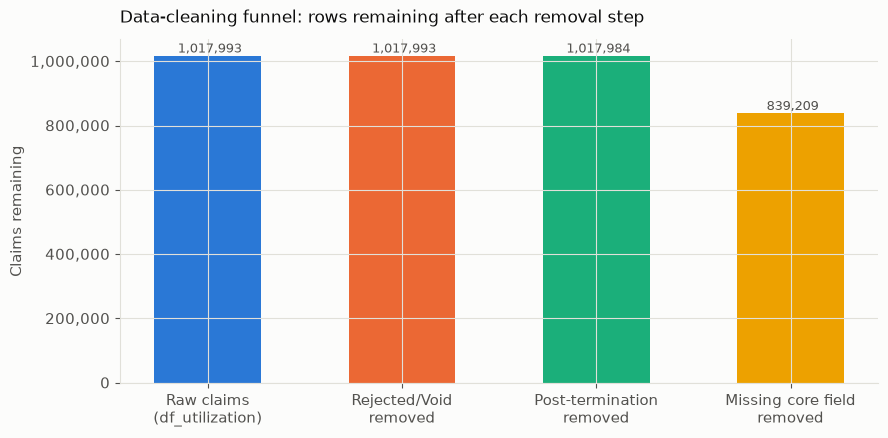

Removed: 0 Rejected/Void, 9 post-termination, 178,775 missing-core-field — 178,784 rows total (17.6%)


In [11]:

funnel_labels = ["Raw claims\n(df_utilization)", "Rejected/Void\nremoved", "Post-termination\nremoved", "Missing core field\nremoved"]
funnel_values = [
    n_raw_claims,
    n_raw_claims - len(df_excluded_claims),
    n_raw_claims - len(df_excluded_claims) - n_post_termination,
    len(df_final),
]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(funnel_labels, funnel_values, color=CATEGORICAL[:4], width=0.55)
ax.set_ylabel("Claims remaining")
ax.set_title("Data-cleaning funnel: rows remaining after each removal step", color=INK, fontsize=12, loc="left", pad=12)
fmt_thousands(ax, axis="y")
for bar, v in zip(bars, funnel_values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f" {v:,}", ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Removed: {len(df_excluded_claims):,} Rejected/Void, {n_post_termination:,} post-termination, "
      f"{n_dropped_core:,} missing-core-field — {n_raw_claims - len(df_final):,} rows total "
      f"({(n_raw_claims - len(df_final)) / n_raw_claims * 100:.1f}%)")


### 8.2 Recovery class imbalance

This is the core challenge for the recovery-risk model: recovered/ex-gratia claims are
a tiny fraction of all claims. A plain-accuracy classifier would just predict "not
recoverable" for everything and still score >99.9% — hence the need for imbalanced-
classification techniques (class weighting, PR-AUC, resampling) at modeling time.
Every chart below compares the tiny recovered group against everything else, to see
what actually distinguishes them.

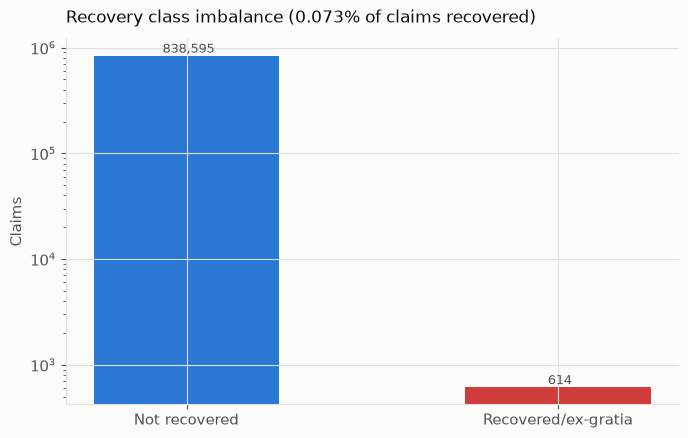

In [12]:

recovery_flag = (df_final["RECOVERY/EX-GRATIA"] > 0)
class_counts = recovery_flag.value_counts().rename({False: "Not recovered", True: "Recovered/ex-gratia"})
recovery_rate = recovery_flag.mean() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(class_counts.index, class_counts.values, color=[CATEGORICAL[0], "#d03b3b"], width=0.5)
ax.set_ylabel("Claims")
ax.set_yscale("log")
ax.set_title(f"Recovery class imbalance ({recovery_rate:.3f}% of claims recovered)", color=INK, fontsize=12, loc="left", pad=12)
for bar, v in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f" {v:,}", ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()

### 8.3 Claim volume vs. recovery rate over time

Two different questions, so two separate axes rather than one dual-axis chart:
overall claim volume (left) can rise or fall for operational reasons (more policies
sold, seasonal illness), while the recovery **rate** (right) tracks whether claims
are getting *riskier* over time — a rising rate with flat volume would be a real signal.

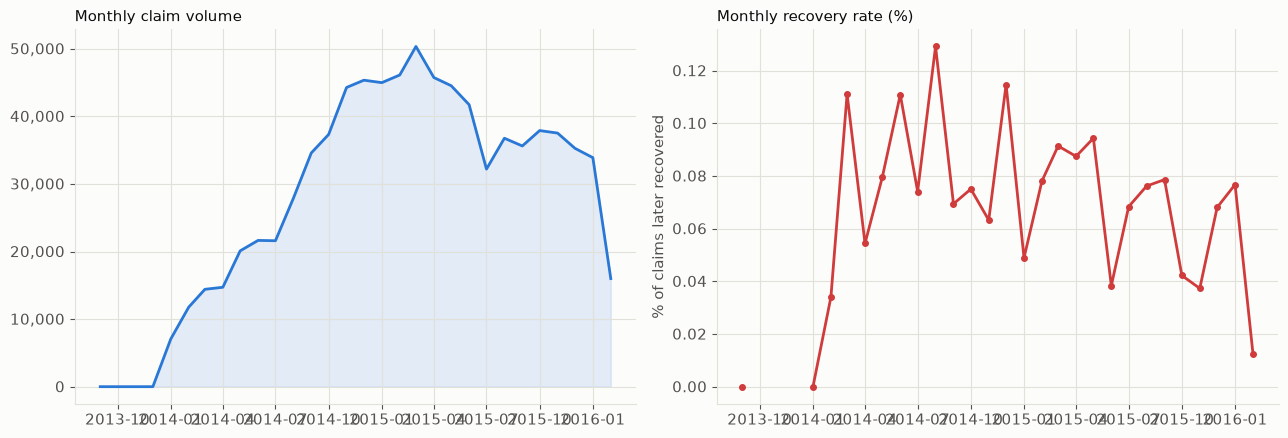

In [13]:

monthly = df_final.dropna(subset=["TXNDATE"]).set_index("TXNDATE")
volume = monthly.resample("MS").size()
recovery_rate_trend = monthly["RECOVERY/EX-GRATIA"].gt(0).resample("MS").mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(volume.index, volume.values, color=CATEGORICAL[0], linewidth=2)
axes[0].fill_between(volume.index, volume.values, color=CATEGORICAL[0], alpha=0.12)
axes[0].set_title("Monthly claim volume", color=INK, fontsize=11, loc="left")
fmt_thousands(axes[0], axis="y")

axes[1].plot(recovery_rate_trend.index, recovery_rate_trend.values, color="#d03b3b", linewidth=2, marker="o", markersize=4)
axes[1].set_title("Monthly recovery rate (%)", color=INK, fontsize=11, loc="left")
axes[1].set_ylabel("% of claims later recovered")

plt.tight_layout()
plt.show()


### 8.4 Claim amount and submission delay: recovered vs. not

If recovered claims are systematically bigger, or submitted with an unusual lag
between service date and reception date, that's a direct, learnable signal for the
model — not just a class-imbalance problem to correct for.

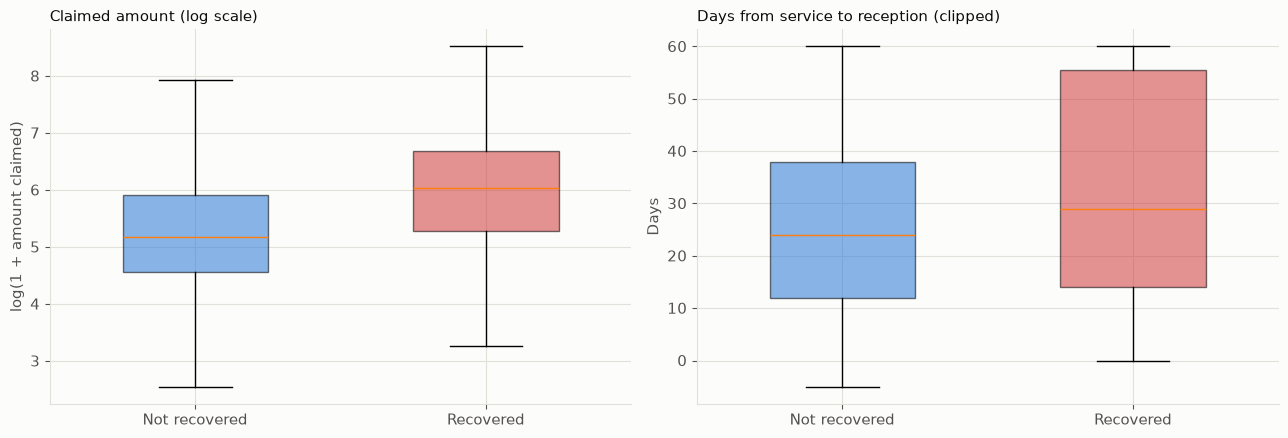

In [14]:

recovered_mask = df_final["RECOVERY/EX-GRATIA"] > 0
days_to_reception = (df_final["RECEPTIONDATE"] - df_final["TXNDATE"]).dt.days

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

amt_groups = [
    np.log1p(df_final.loc[~recovered_mask, "TOTALAMOUNTCLAIMED"].clip(lower=0)),
    np.log1p(df_final.loc[recovered_mask, "TOTALAMOUNTCLAIMED"].clip(lower=0)),
]
bp0 = axes[0].boxplot(amt_groups, tick_labels=["Not recovered", "Recovered"], patch_artist=True, showfliers=False, widths=0.5)
for patch, color in zip(bp0["boxes"], [CATEGORICAL[0], "#d03b3b"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
axes[0].set_title("Claimed amount (log scale)", color=INK, fontsize=11, loc="left")
axes[0].set_ylabel("log(1 + amount claimed)")

days_groups = [
    days_to_reception[~recovered_mask].dropna().clip(lower=-5, upper=60),
    days_to_reception[recovered_mask].dropna().clip(lower=-5, upper=60),
]
bp1 = axes[1].boxplot(days_groups, tick_labels=["Not recovered", "Recovered"], patch_artist=True, showfliers=False, widths=0.5)
for patch, color in zip(bp1["boxes"], [CATEGORICAL[0], "#d03b3b"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
axes[1].set_title("Days from service to reception (clipped)", color=INK, fontsize=11, loc="left")
axes[1].set_ylabel("Days")

plt.tight_layout()
plt.show()


### 8.5 Recovery rate by diagnosis (ICD chapter)

Which diagnosis categories carry the highest recovery risk — restricted to chapters
with at least 300 claims so a handful of small samples don't distort the ranking.
This is exactly the kind of pattern an auditor would want surfaced before payment,
not after.

C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\2769449705.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diag_stats = df_final.groupby("ICD CHAPTER").agg(


C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\2769449705.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


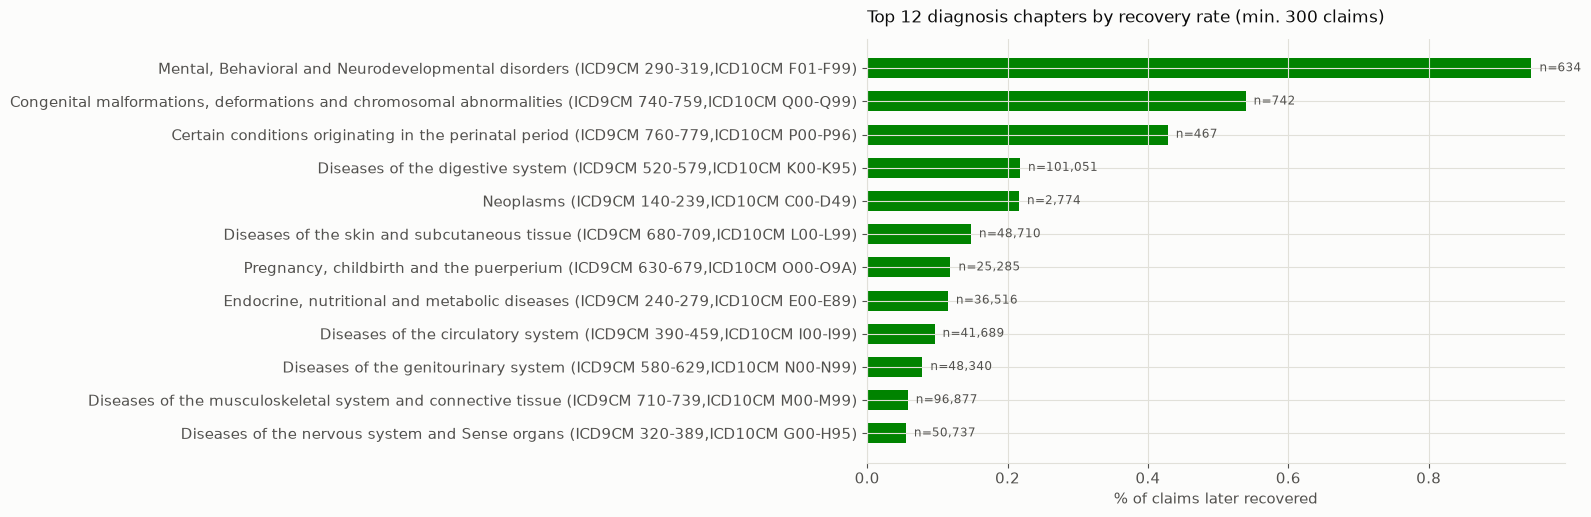

In [15]:

diag_stats = df_final.groupby("ICD CHAPTER").agg(
    claims=("RECOVERY/EX-GRATIA", "size"),
    recovered=("RECOVERY/EX-GRATIA", lambda s: (s > 0).sum()),
)
diag_stats["rate_pct"] = diag_stats["recovered"] / diag_stats["claims"] * 100
diag_stats = diag_stats[diag_stats["claims"] >= 300].sort_values("rate_pct", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(diag_stats.index[::-1], diag_stats["rate_pct"].values[::-1], color=CATEGORICAL[5], height=0.6)
ax.set_xlabel("% of claims later recovered")
ax.set_title("Top 12 diagnosis chapters by recovery rate (min. 300 claims)", color=INK, fontsize=12, loc="left", pad=12)
for bar, n in zip(bars, diag_stats["claims"].values[::-1]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  n={n:,}", va="center", color=INK_SECONDARY, fontsize=8.5)
plt.tight_layout()
plt.show()


### 8.6 Recovery rate by claim type and network type

`FOB` is the service category (in-patient, out-patient, dental, maternity, ...);
`NETWORK TYPE` reflects which provider network handled the claim. Both are known
the moment a claim is submitted, so both are legitimate pre-adjudication risk cuts.

C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\3723100176.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = df_final.groupby(col).agg(
C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\3723100176.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = df_final.groupby(col).agg(


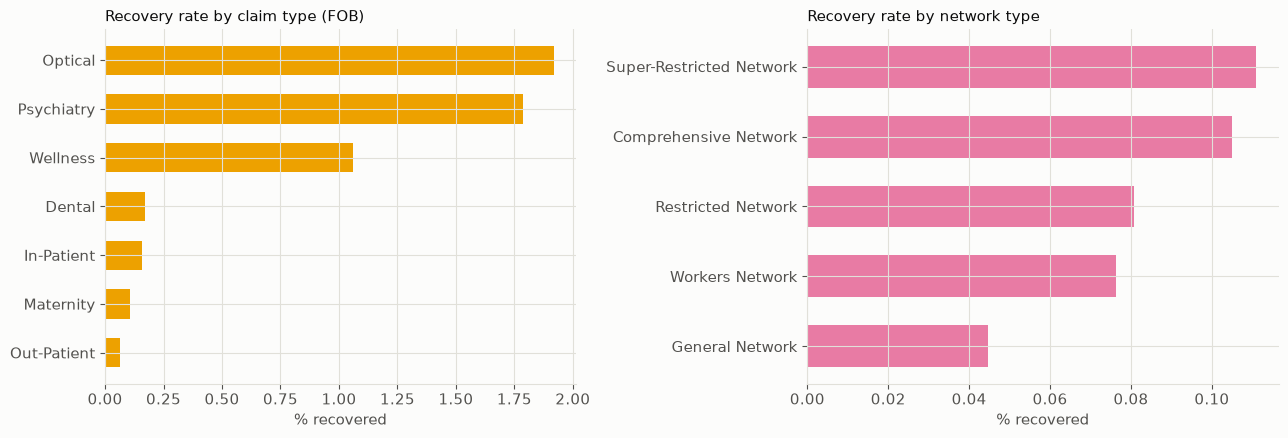

In [16]:

def recovery_rate_by(col, min_claims=200):
    stats = df_final.groupby(col).agg(
        claims=("RECOVERY/EX-GRATIA", "size"),
        recovered=("RECOVERY/EX-GRATIA", lambda s: (s > 0).sum()),
    )
    stats["rate_pct"] = stats["recovered"] / stats["claims"] * 100
    return stats[stats["claims"] >= min_claims].sort_values("rate_pct", ascending=False)

fob_stats = recovery_rate_by("FOB")
network_stats = recovery_rate_by("NETWORK TYPE")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].barh(fob_stats.index[::-1], fob_stats["rate_pct"].values[::-1], color=CATEGORICAL[3], height=0.6)
axes[0].set_title("Recovery rate by claim type (FOB)", color=INK, fontsize=11, loc="left")
axes[0].set_xlabel("% recovered")

axes[1].barh(network_stats.index[::-1], network_stats["rate_pct"].values[::-1], color=CATEGORICAL[4], height=0.6)
axes[1].set_title("Recovery rate by network type", color=INK, fontsize=11, loc="left")
axes[1].set_xlabel("% recovered")

plt.tight_layout()
plt.show()


### 8.7 Recovery risk by provider type

Which provider types generate the most recoverable money and the highest recovery
rate — a first pass at the "rank providers/networks by recoverable claims" BI view.
Restricted to provider types with at least 500 claims so the rate isn't noise.

C:\Users\Chayma\AppData\Local\Temp\ipykernel_51548\972681758.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  provider_stats = df_final.groupby("PROVIDERTYPE").agg(


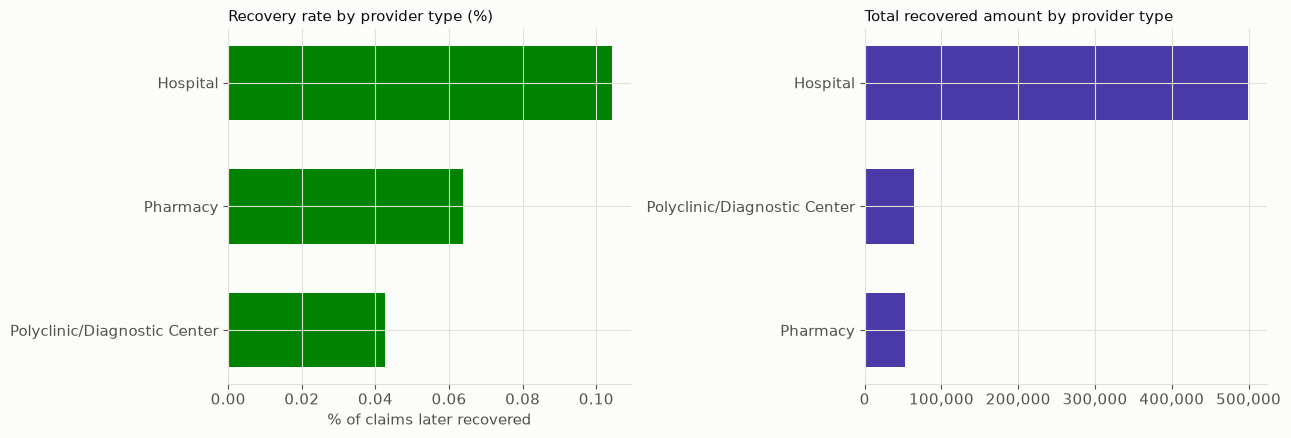

,claims,recovered_claims,recovered_amount,recovery_rate_pct
PROVIDERTYPE,,,,
Hospital,314955,328,499279.88,0.104142
Polyclinic/Diagnostic Center,225888,96,64326.50,0.042499
Pharmacy,298314,190,52193.82,0.063691


In [17]:

provider_stats = df_final.groupby("PROVIDERTYPE").agg(
    claims=("RECOVERY/EX-GRATIA", "size"),
    recovered_claims=("RECOVERY/EX-GRATIA", lambda s: (s > 0).sum()),
    recovered_amount=("RECOVERY/EX-GRATIA", "sum"),
)
provider_stats["recovery_rate_pct"] = provider_stats["recovered_claims"] / provider_stats["claims"] * 100
provider_stats = provider_stats[provider_stats["claims"] >= 500].sort_values("recovery_rate_pct", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].barh(provider_stats.index[::-1], provider_stats["recovery_rate_pct"].values[::-1], color=CATEGORICAL[5], height=0.6)
axes[0].set_title("Recovery rate by provider type (%)", color=INK, fontsize=11, loc="left")
axes[0].set_xlabel("% of claims later recovered")

by_amount = provider_stats.sort_values("recovered_amount", ascending=False)
axes[1].barh(by_amount.index[::-1], by_amount["recovered_amount"].values[::-1], color=CATEGORICAL[6], height=0.6)
axes[1].set_title("Total recovered amount by provider type", color=INK, fontsize=11, loc="left")
fmt_thousands(axes[1], axis="x")

plt.tight_layout()
plt.show()
provider_stats.sort_values("recovered_amount", ascending=False)


### 8.8 Recovery rate by age band and gender

Demographic cuts — useful to check the model isn't just re-learning "older
beneficiaries claim more" (volume) versus an actual difference in recovery
*rate* (risk).

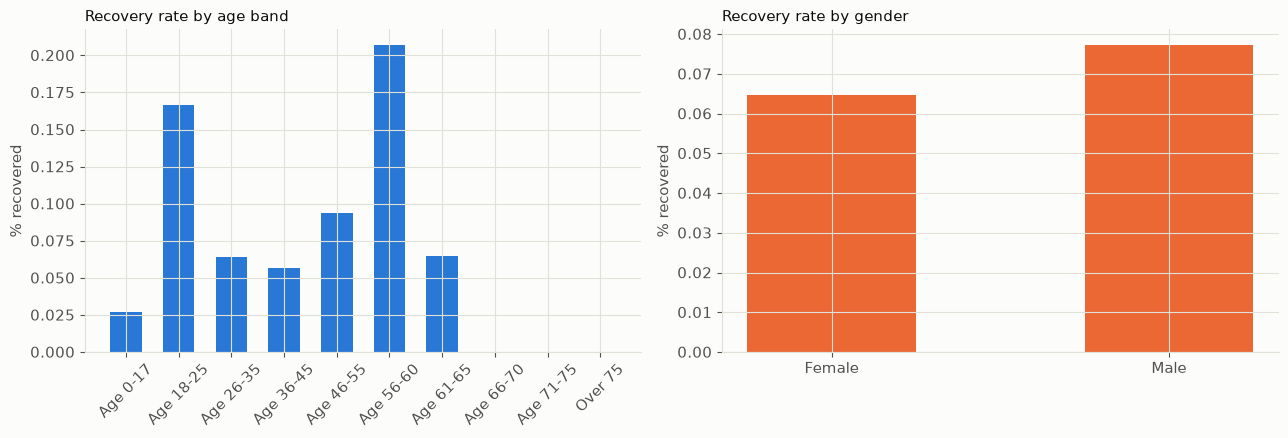

In [18]:

ageband_order = sorted(df_final["AGEBAND"].dropna().unique(), key=lambda s: int(re.search(r"\d+", s).group()) if re.search(r"\d+", s) else 999)
age_stats = df_final.groupby("AGEBAND", observed=True).agg(
    claims=("RECOVERY/EX-GRATIA", "size"),
    recovered=("RECOVERY/EX-GRATIA", lambda s: (s > 0).sum()),
)
age_stats["rate_pct"] = age_stats["recovered"] / age_stats["claims"] * 100
age_stats = age_stats.reindex(ageband_order)

gender_stats = df_final.groupby("GENDER", observed=True).agg(
    claims=("RECOVERY/EX-GRATIA", "size"),
    recovered=("RECOVERY/EX-GRATIA", lambda s: (s > 0).sum()),
)
gender_stats["rate_pct"] = gender_stats["recovered"] / gender_stats["claims"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(age_stats.index, age_stats["rate_pct"].values, color=CATEGORICAL[0], width=0.6)
axes[0].set_title("Recovery rate by age band", color=INK, fontsize=11, loc="left")
axes[0].set_ylabel("% recovered")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(gender_stats.index, gender_stats["rate_pct"].values, color=CATEGORICAL[1], width=0.5)
axes[1].set_title("Recovery rate by gender", color=INK, fontsize=11, loc="left")
axes[1].set_ylabel("% recovered")

plt.tight_layout()
plt.show()


### 8.9 Recovery / ex-gratia amount distribution

Distribution of recovery amounts among the claims that had a non-zero `RECOVERY/EX-GRATIA` value —
what does a "typical" recovered claim actually cost, and how heavy is the tail?

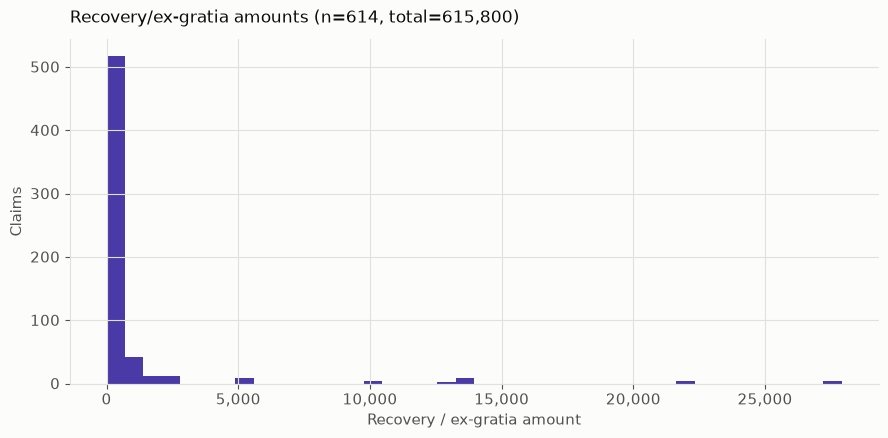

In [19]:

if not df_recovery.empty:
    rec = df_recovery["RECOVERY/EX-GRATIA"]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.hist(rec, bins=40, color=CATEGORICAL[6])
    ax.set_xlabel("Recovery / ex-gratia amount")
    ax.set_ylabel("Claims")
    ax.set_title(f"Recovery/ex-gratia amounts (n={len(rec):,}, total={rec.sum():,.0f})", color=INK, fontsize=12, loc="left", pad=12)
    fmt_thousands(ax, axis="y")
    fmt_thousands(ax, axis="x")
    plt.tight_layout()
    plt.show()
else:
    print("No recovery/ex-gratia claims in this dataset.")


## 9. ML-ready feature set (recovery-risk model)

`df_final` is a clean, analyst-friendly dataset, but it still mixes pre-adjudication
facts (known when the claim is *submitted*: patient profile, diagnosis, provider,
claim amount, dates) with post-adjudication facts (only known once the claim has
already been processed/settled/recovered: `STATUS`, `TOTALPAYABLE`, `PAYERSHARE`,
`DEDUCTIONAMOUNT`, `RECOVERYTYPE`, `PO`/`ORDERDATE`/`CHEQUENBR`/`SETTLEDATE`,
`ASSESSMENT`, recovery notes).

A model trained to predict recovery risk **at submission time** must never see the
post-adjudication columns as features — only as the label. This section:

1. Builds the label: `RECOVERY_FLAG` = was this claim later flagged for recovery/ex-gratia.
2. Engineers pre-adjudication features (amount ratios, time gaps, provider/network history).
3. Encodes categoricals (one-hot for low-cardinality, frequency-encoding for
   high-cardinality columns like `PROVIDER`) and scales numeric features.
4. Exports `claims_ml_ready.csv` for the modeling notebook.

**Note on frequency encoding:** it's computed over the *whole* dataset here for
simplicity. In an actual train/test split, recompute it on the training fold only
(fit on train, transform on test) to avoid leaking test-set information.

In [20]:

df_ml = df_final  # cheap thanks to copy-on-write; df_final was already exported to CSV in section 7

# --- 9.1 Label ---
df_ml["RECOVERY_FLAG"] = (df_ml["RECOVERY/EX-GRATIA"] > 0).astype(int)

# --- 9.2 Columns that must NOT be used as features ---
LEAKAGE_COLS = [c for c in [
    "STATUS", "STATUS_DESCRIPTION", "TOTALPAYABLE", "PAYERSHARE", "BENEFICIARYSHAREAPPROVED",
    "DEDUCTIONAMOUNT", "RECOVERY/EX-GRATIA", "RECOVERY/EX-GRATIA_WAS_MISSING", "RECOVERYTYPE",
    "PO", "ORDERDATE", "CHEQUENBR", "SETTLEDATE", "ASSESSMENT",
    "Recovery Notes", "RecoveryNotes", "PAYABLE NON IP CONSULTATION",
    "TOTALPAYABLE_WAS_MISSING", "PAYERSHARE_WAS_MISSING", "BENEFICIARYSHAREAPPROVED_WAS_MISSING",
    "DEDUCTIONAMOUNT_WAS_MISSING",
] if c in df_ml.columns]

# Identifiers / free-text / administrative metadata: not generalizable model inputs.
ID_AND_METADATA_COLS = [c for c in [
    "CLAIMID", "AUTHORIZATIONNBR", "INVOICENBR", "BENEFICIARYID", "BENEFICIARYIDENTIFIER",
    "MASTERCONTRACT", "CONTRACT", "PRINCIPAL", "BENEFICIARY", "PAYER",
    "POLICYNO", "POLICYNUMBER", "CARDNUMBER", "NATIONALIDENTITYNO",
    "ENDORSEMENTID", "ENDOTYPE", "ENDORSEMENTDATE", "ISSUEDATE",
    "REPORT_TYPE", "source_file", "BENEF_SHEET",
    "PAYERAMOUNTCLAIMED_WAS_MISSING", "BENEFICIARYAMOUNTCLAIMED_WAS_MISSING", "TOTALAMOUNTCLAIMED_WAS_MISSING",
] if c in df_ml.columns]

print(f"Excluding {len(LEAKAGE_COLS)} post-adjudication (leakage) columns: {LEAKAGE_COLS}")
print(f"Excluding {len(ID_AND_METADATA_COLS)} identifier/metadata columns: {ID_AND_METADATA_COLS}")

# --- 9.3 Feature engineering (all pre-adjudication: known at submission time) ---
# DAYS_TO_RECEPTION assumes scoring happens once the claim record exists in the
# system — i.e. at/after RECEPTIONDATE, not at the moment service was rendered.
# That's the only realistic deployment scenario: a claim can't be scored before
# it's been submitted, since there's no record to score yet. So both TXNDATE and
# RECEPTIONDATE (and their gap) are always known at scoring time — not leakage.
df_ml["DAYS_TO_RECEPTION"] = (df_ml["RECEPTIONDATE"] - df_ml["TXNDATE"]).dt.days if "RECEPTIONDATE" in df_ml.columns else np.nan
df_ml["POLICY_DAYS_REMAINING"] = (df_ml["EXPIRYDATE"] - df_ml["TXNDATE"]).dt.days if "EXPIRYDATE" in df_ml.columns else np.nan
df_ml["MEMBER_TENURE_DAYS"] = (df_ml["TXNDATE"] - df_ml["MEMBER START DATE"]).dt.days if "MEMBER START DATE" in df_ml.columns else np.nan
# CLAIM_YEAR is used both as a feature (known at submission time) and as the
# temporal split key in the modeling notebook (train on past years, validate/test
# on future years) — a real deployment scenario never trains on data from the
# future relative to the claim being scored.
df_ml["CLAIM_YEAR"] = df_ml["TXNDATE"].dt.year
df_ml["CLAIM_MONTH"] = df_ml["TXNDATE"].dt.month
df_ml["CLAIM_QUARTER"] = df_ml["TXNDATE"].dt.quarter
df_ml["CLAIM_IS_WEEKEND"] = df_ml["TXNDATE"].dt.dayofweek >= 5
df_ml["CLAIM_AMOUNT_LOG"] = np.log1p(df_ml["TOTALAMOUNTCLAIMED"].clip(lower=0))
df_ml["RESUBMISSION_FLAG"] = df_ml["RESUBMISSION"].astype(str).str.strip().str.upper().isin(["YES", "Y", "TRUE", "1"]) if "RESUBMISSION" in df_ml.columns else False

# Provider/network historical claim volume — a proxy for how established/high-traffic
# a provider is; high-cardinality so kept as a *count*, not one-hot encoded.
if "PROVIDER" in df_ml.columns:
    df_ml["PROVIDER_CLAIM_FREQ"] = df_ml["PROVIDER"].map(df_ml["PROVIDER"].value_counts())
if "NETWORK" in df_ml.columns:
    df_ml["NETWORK_CLAIM_FREQ"] = df_ml["NETWORK"].map(df_ml["NETWORK"].value_counts())

# --- 9.4 Peer-deviation features ---
# Is this claim's amount unusual for its own cohort (same diagnosis chapter, age
# band, and service type)? A claim that's 5x its peer group's median cost is a much
# stronger signal than the raw amount alone. NETWORK is deliberately left out of the
# grouping key — combined with the other three it fragments peer groups too small
# for a stable median/std.
PEER_GROUP_COLS = [c for c in ["ICD CHAPTER", "AGEBAND", "FOB"] if c in df_ml.columns]
if PEER_GROUP_COLS:
    peer_amount = df_ml.groupby(PEER_GROUP_COLS, observed=True)["TOTALAMOUNTCLAIMED"]
    df_ml["PEER_MEDIAN"] = peer_amount.transform("median")
    df_ml["PEER_MEAN"] = peer_amount.transform("mean")
    df_ml["PEER_STD"] = peer_amount.transform("std").fillna(0.0)
    df_ml["PEER_ZSCORE"] = (
        (df_ml["TOTALAMOUNTCLAIMED"] - df_ml["PEER_MEAN"]) / df_ml["PEER_STD"].replace(0, np.nan)
    ).fillna(0.0)
    df_ml["AMOUNT_OVER_MEDIAN"] = (
        df_ml["TOTALAMOUNTCLAIMED"] / df_ml["PEER_MEDIAN"].replace(0, np.nan)
    ).fillna(1.0)  # neutral ratio (claim == peer group) when the median is undefined/zero
    print(f"Peer-deviation features built on groups: {PEER_GROUP_COLS}")

# --- 9.5 Provider historical risk ---
# A provider's own billing pattern (not just how often they appear) — average,
# median, and spread of amounts they've claimed. Recoveries are rare enough that
# provider-level behavior is one of the more predictive signals available.
if "PROVIDER" in df_ml.columns:
    provider_amount = df_ml.groupby("PROVIDER", observed=True)["TOTALAMOUNTCLAIMED"]
    df_ml["PROVIDER_AVG_AMOUNT"] = provider_amount.transform("mean")
    df_ml["PROVIDER_MEDIAN_AMOUNT"] = provider_amount.transform("median")
    df_ml["PROVIDER_STD_AMOUNT"] = provider_amount.transform("std").fillna(0.0)

print(f"\ndf_ml shape after feature engineering: {df_ml.shape}")


Excluding 14 post-adjudication (leakage) columns: ['STATUS', 'STATUS_DESCRIPTION', 'TOTALPAYABLE', 'PAYERSHARE', 'BENEFICIARYSHAREAPPROVED', 'DEDUCTIONAMOUNT', 'RECOVERY/EX-GRATIA', 'RECOVERYTYPE', 'PO', 'ORDERDATE', 'CHEQUENBR', 'SETTLEDATE', 'ASSESSMENT', 'PAYABLE NON IP CONSULTATION']
Excluding 21 identifier/metadata columns: ['CLAIMID', 'AUTHORIZATIONNBR', 'INVOICENBR', 'BENEFICIARYID', 'BENEFICIARYIDENTIFIER', 'MASTERCONTRACT', 'CONTRACT', 'PRINCIPAL', 'BENEFICIARY', 'PAYER', 'POLICYNO', 'POLICYNUMBER', 'CARDNUMBER', 'NATIONALIDENTITYNO', 'ENDORSEMENTID', 'ENDOTYPE', 'ENDORSEMENTDATE', 'ISSUEDATE', 'REPORT_TYPE', 'source_file', 'BENEF_SHEET']


Peer-deviation features built on groups: ['ICD CHAPTER', 'AGEBAND', 'FOB']

df_ml shape after feature engineering: (839209, 99)


In [21]:

from sklearn.preprocessing import StandardScaler

TARGET_COL = "RECOVERY_FLAG"
DROP_COLS = list(set(LEAKAGE_COLS + ID_AND_METADATA_COLS))

feature_df = df_ml.drop(columns=DROP_COLS + [TARGET_COL])

# Raw datetime columns aren't usable as model inputs directly — their signal is
# already captured in the engineered *_DAYS / CLAIM_MONTH etc. features above.
datetime_cols = [c for c in feature_df.columns if pd.api.types.is_datetime64_any_dtype(feature_df[c])]
feature_df = feature_df.drop(columns=datetime_cols)
print(f"Dropped {len(datetime_cols)} raw datetime columns (superseded by engineered features): {datetime_cols}")

# Capture the genuinely continuous numeric columns BEFORE one-hot encoding and
# before casting booleans to int — only these get scaled later. One-hot dummies
# and boolean flags are already on a comparable [0, 1] scale; standardizing them
# adds no value and (with ~80 dummy columns across 839k rows) roughly doubles the
# memory StandardScaler needs for no benefit.
continuous_numeric_cols = feature_df.select_dtypes(include=[np.number]).columns.tolist()

# CLAIM_YEAR is kept as a raw, unscaled integer — the modeling notebook needs the
# actual year values (2013/2014/2015/2016) to build a temporal train/valid/test
# split, which a standardized z-score would destroy. Tree models don't need it
# scaled anyway; a linear baseline can standardize it itself using train-fold stats.
if "CLAIM_YEAR" in continuous_numeric_cols:
    continuous_numeric_cols.remove("CLAIM_YEAR")

bool_cols = [c for c in feature_df.columns if feature_df[c].dtype == bool]
feature_df[bool_cols] = feature_df[bool_cols].astype(int)

# NOTE: optimize_dtypes() (section 2) converted repetitive string columns to
# 'category' dtype for memory efficiency, so both object AND category columns
# need to be picked up here, not just object.
categorical_cols = [
    c for c in feature_df.columns
    if feature_df[c].dtype == object or isinstance(feature_df[c].dtype, pd.CategoricalDtype)
]
low_card_cols = [c for c in categorical_cols if feature_df[c].nunique(dropna=True) <= 15]
high_card_cols = [c for c in categorical_cols if c not in low_card_cols]

print(f"\nOne-hot encoding {len(low_card_cols)} low-cardinality columns: {low_card_cols}")
print(f"Frequency-encoding {len(high_card_cols)} high-cardinality columns: {high_card_cols}")

for col in low_card_cols:
    feature_df[col] = feature_df[col].astype(object).fillna("Unknown")
feature_df = pd.get_dummies(feature_df, columns=low_card_cols, prefix=low_card_cols, dtype=int)

for col in high_card_cols:
    col_vals = feature_df[col].astype(object)
    freq = col_vals.value_counts(normalize=True)
    feature_df[col + "_FREQ"] = col_vals.map(freq).fillna(0.0)
    continuous_numeric_cols.append(col + "_FREQ")
feature_df = feature_df.drop(columns=high_card_cols)

# Any numeric NaNs left (e.g. LOS blank for outpatient claims, ratios where the
# denominator was 0) get a neutral 0 fill *and* a flag, so the model can tell
# "genuinely zero" from "not applicable" apart.
for col in continuous_numeric_cols:
    n_na = feature_df[col].isna().sum()
    if n_na:
        feature_df[col + "_WAS_NA"] = feature_df[col].isna().astype(int)
        feature_df[col] = feature_df[col].fillna(0.0)

# Zero-variance columns (e.g. a one-hot dummy for a category every row shares,
# like CURRENCY when every claim is AED) carry no signal for a model to learn
# from, and StandardScaler on a constant column divides by a ~zero std — drop
# them before scaling.
constant_cols = [c for c in feature_df.columns if feature_df[c].nunique(dropna=False) <= 1]
if constant_cols:
    feature_df = feature_df.drop(columns=constant_cols)
    print(f"Dropped {len(constant_cols)} zero-variance features: {constant_cols}")

numeric_cols = [c for c in continuous_numeric_cols if c in feature_df.columns]
scaler = StandardScaler()
feature_df[numeric_cols] = scaler.fit_transform(feature_df[numeric_cols])
print(f"Scaled {len(numeric_cols)} continuous numeric columns (one-hot/flag columns left as 0/1): {numeric_cols}")

df_ml_ready = pd.concat([feature_df, df_ml[TARGET_COL]], axis=1)
print(f"\nFinal ML-ready feature matrix: {df_ml_ready.shape[0]:,} rows x {df_ml_ready.shape[1] - 1:,} features + target")
print(f"Positive class (RECOVERY_FLAG=1): {df_ml_ready[TARGET_COL].sum():,} ({df_ml_ready[TARGET_COL].mean() * 100:.3f}%)")
df_ml_ready.head()


Dropped 9 raw datetime columns (superseded by engineered features): ['EFFECTIVEDATE', 'EXPIRYDATE', 'DOB', 'TXNDATE', 'DISCHARGEDATE', 'MEMBER START DATE', 'RECEPTIONDATE', 'CONTRACTEFFDATE', 'CONTRACTEXPDATE']



One-hot encoding 18 low-cardinality columns: ['BRANCH', 'GENDER', 'MARITAL STATUS', 'AGEBAND', 'DEPENDENCY', 'BENEF-STATUS', 'NETWORK TYPE', 'REPORTING AUTHORITY', 'FOB', 'CHRONIC', 'PREEXISTING', 'CLAIMTYPE', 'RESUBMISSION', 'PROVIDER EMIRATE', 'PROVIDERTYPE', 'CURRENCY', 'CLAIM CATEGORY', 'MARITALSTATUS']
Frequency-encoding 10 high-cardinality columns: ['NATIONALITY', 'EMPNO', 'CATEGORY', 'NETWORK', 'PROVIDERCOUNTRY', 'PROVIDER GROUP', 'PROVIDER', 'ICD CHAPTER', 'ICD SUB CHAPTER', 'PRODUCT']


Dropped 1 zero-variance features: ['CURRENCY_Arab Emirates Dirham']


Scaled 33 continuous numeric columns (one-hot/flag columns left as 0/1): ['AGE', 'LOS', 'PAYERAMOUNTCLAIMED', 'BENEFICIARYAMOUNTCLAIMED', 'TOTALAMOUNTCLAIMED', 'NETPREMIUM', 'GROSSPREMIUM', 'DAYS_TO_RECEPTION', 'POLICY_DAYS_REMAINING', 'MEMBER_TENURE_DAYS', 'CLAIM_MONTH', 'CLAIM_QUARTER', 'CLAIM_AMOUNT_LOG', 'PROVIDER_CLAIM_FREQ', 'NETWORK_CLAIM_FREQ', 'PEER_MEDIAN', 'PEER_MEAN', 'PEER_STD', 'PEER_ZSCORE', 'AMOUNT_OVER_MEDIAN', 'PROVIDER_AVG_AMOUNT', 'PROVIDER_MEDIAN_AMOUNT', 'PROVIDER_STD_AMOUNT', 'NATIONALITY_FREQ', 'EMPNO_FREQ', 'CATEGORY_FREQ', 'NETWORK_FREQ', 'PROVIDERCOUNTRY_FREQ', 'PROVIDER GROUP_FREQ', 'PROVIDER_FREQ', 'ICD CHAPTER_FREQ', 'ICD SUB CHAPTER_FREQ', 'PRODUCT_FREQ']

Final ML-ready feature matrix: 839,209 rows x 109 features + target
Positive class (RECOVERY_FLAG=1): 614 (0.073%)


,AGE,LOS,PAYERAMOUNTCLAIMED,BENEFICIARYAMOUNTCLAIMED,TOTALAMOUNTCLAIMED,NETPREMIUM,GROSSPREMIUM,DAYS_TO_RECEPTION,POLICY_DAYS_REMAINING,MEMBER_TENURE_DAYS,CLAIM_YEAR,CLAIM_MONTH,CLAIM_QUARTER,CLAIM_IS_WEEKEND,CLAIM_AMOUNT_LOG,RESUBMISSION_FLAG,PROVIDER_CLAIM_FREQ,NETWORK_CLAIM_FREQ,PEER_MEDIAN,PEER_MEAN,PEER_STD,PEER_ZSCORE,AMOUNT_OVER_MEDIAN,PROVIDER_AVG_AMOUNT,PROVIDER_MEDIAN_AMOUNT,PROVIDER_STD_AMOUNT,BRANCH_Abu Dhabi (H.O),BRANCH_Abu Dhabi (H.O) Domestic,BRANCH_Main,GENDER_Female,...,PROVIDER EMIRATE_Ras Al Khaimah,PROVIDER EMIRATE_Sharjah,PROVIDER EMIRATE_Um Al Quwain,PROVIDER EMIRATE_Unknown,PROVIDERTYPE_Hospital,PROVIDERTYPE_International Provider,PROVIDERTYPE_Pharmacy,PROVIDERTYPE_Polyclinic/Diagnostic Center,CLAIM CATEGORY_Outstanding/Open Authorization,CLAIM CATEGORY_Outstanding/Under Process,CLAIM CATEGORY_Paid,CLAIM CATEGORY_To Be Paid,MARITALSTATUS_Married,MARITALSTATUS_Single,MARITALSTATUS_Unknown,NATIONALITY_FREQ,EMPNO_FREQ,CATEGORY_FREQ,NETWORK_FREQ,PROVIDERCOUNTRY_FREQ,PROVIDER GROUP_FREQ,PROVIDER_FREQ,ICD CHAPTER_FREQ,ICD SUB CHAPTER_FREQ,PRODUCT_FREQ,LOS_WAS_NA,NETPREMIUM_WAS_NA,GROSSPREMIUM_WAS_NA,DAYS_TO_RECEPTION_WAS_NA,RECOVERY_FLAG
0,0.751498,-0.026058,0.586422,-0.185094,0.570727,0.255346,0.169616,-0.376865,1.637743,-0.490042,2014,-1.537218,-1.310771,1,1.740579,0,-0.743885,1.041315,0.233035,0.264816,0.218420,0.823898,0.449593,2.058107,1.785521,0.588020,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,1.484948,-0.743885,0.088133,-0.350885,-0.63058,1,0,0,0,0
1,0.751498,-0.026058,0.057959,-0.185094,0.045624,0.255346,0.169616,-0.423545,1.618134,-0.483942,2014,-1.537218,-1.310771,0,0.845144,0,-0.743885,1.041315,0.233035,0.264816,0.218420,-0.171963,-0.118048,2.058107,1.785521,0.588020,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,1.484948,-0.743885,0.088133,-0.350885,-0.63058,1,0,0,0,0
2,0.751498,-0.026058,0.219008,0.221004,0.231904,0.255346,0.169616,-0.143467,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.282034,0,-0.605944,1.041315,-0.126610,-0.178950,-0.225402,1.818999,0.899629,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,1.628384,2.345541,-0.63058,1,0,0,0,0
3,0.751498,-0.026058,0.194947,1.356289,0.281395,0.255346,0.169616,-0.073447,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.367297,0,-0.605944,1.041315,-0.126610,-0.178950,-0.225402,2.096844,1.043140,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,1.628384,2.345541,-0.63058,1,0,0,0,0
4,0.751498,-0.026058,0.195132,1.357345,0.281647,0.255346,0.169616,-0.750303,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.367710,0,-0.605944,1.041315,-0.053683,-0.050152,-0.080797,1.053353,0.676111,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,0.088133,-0.074614,-0.63058,1,0,0,0,0


In [22]:

ml_ready_output = PROCESSED_DIR / "claims_ml_ready.csv"
df_ml_ready.to_csv(ml_ready_output, index=False)
print(f"Saved: {ml_ready_output.name} ({df_ml_ready.shape[0]:,} rows, {df_ml_ready.shape[1]:,} columns)")


Saved: claims_ml_ready.csv (839,209 rows, 110 columns)


## Summary

| Dataset | Rows | Notes |
|---|---|---|
| `df_utilization` | combined raw claims | every sheet of every claims workbook |
| `df_valid_claims` | excludes Rejected/Void | |
| `df_final` | cleaned claims + beneficiary merge | Rejected/Void, post-termination, and missing-core-field rows deleted; exported as `consolidated_claims_all_reports.csv` |
| `df_excluded_claims` | Rejected/Void only | exported as `excluded_rejected_void_claims.csv` |
| `df_post_termination` | serviced after policy expiry | exported as `excluded_post_termination_claims.csv` |
| `df_recovery` | non-zero recovery/ex-gratia | exported as `recovery_ex_gratia_claims.csv` |
| `df_ml_ready` | encoded, scaled, leakage-free features + `RECOVERY_FLAG` label | exported as `claims_ml_ready.csv` |

All processed CSVs are written to `data/processed/`.

**Key fixes made in this pass:**
- The beneficiary merge previously joined on two *different* identifier systems
  (`BENEFICIARYIDENTIFIER` vs `BENEFICIARYID`) and silently matched 0 rows —
  every beneficiary-sourced column (`POLICYNUMBER`, `NETWORK`, `PRODUCT`,
  premiums, etc.) was 100% NaN. Fixed by joining on beneficiary name + DOB.
- `REINSURER` is genuinely blank in the source workbooks (only one file ever
  populates it) — not a pipeline bug, a real gap in the source data; it's now
  dropped as a sparse column rather than left in as a mostly-empty field.
- Post-termination claims are now **deleted** from `df_final`, not just flagged.
- Rows missing a core modeling field (amount, date, status, provider type,
  claim ID, diagnosis) are deleted rather than silently filled.
- Section 9 builds a leakage-safe, encoded, scaled ML-ready export for the
  recovery-risk classifier, explicitly excluding every post-adjudication column.